# Explorer 07 - Artist clustering

**Purpose.** Build artist feature vectors, add node2vec graph embeddings, reduce with UMAP, and cluster with HDBSCAN.

**Feeds main report section:** 5.6 Artist clustering

**Modules used:** `vinyl.clustering`, `vinyl.networks`

**Tables read:** `release_artists`, `release_styles`, `release_formats`, `release_labels`

This is a working notebook. It can be messy; anything that goes into the report is re-run from `main.ipynb` through the same functions in `vinyl/`.

**Status.** `clustering.node2vec_embeddings` and `clustering.combine_features` were implemented in T10. Expected runtime on the full 2026 data: about 30-60 minutes (node2vec 10-30 min, then two UMAP runs and HDBSCAN at a few minutes each); with `REUSE_EMBEDDINGS = True` a rerun loads the saved files and skips them.

In [1]:
# Make the `vinyl` package importable from the explorers/ folder.
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "explorers":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
from pyspark.sql import functions as F
from vinyl import config, ingest

spark = ingest.get_spark(app_name="vinyl-07-clustering")
from vinyl import clustering, networks, viz

In [2]:
snapshot = config.MAIN_SNAPSHOT  # "2026"
release_artists = ingest.read_table(spark, snapshot, "release_artists")
release_styles = ingest.read_table(spark, snapshot, "release_styles")
release_genres = ingest.read_table(spark, snapshot, "release_genres")
release_formats = ingest.read_table(spark, snapshot, "release_formats")
release_labels = ingest.read_table(spark, snapshot, "release_labels")

## 1. Artist profile features (Spark)

In [3]:
real_artists = release_artists.where(~F.col("artist_id").isin(list(networks.PLACEHOLDER_ARTIST_IDS)))
profile = clustering.artist_profile(real_artists, release_formats, release_labels, min_releases=5).cache()
print(profile.count(), "artists kept")
profile.describe().show()

194105 artists kept


+-------+-----------------+-----------+------------------+------------------+------------------+------------------+-----------------+-------------------+-------------------+-------------------+------------------+
|summary|        artist_id|artist_name|        n_releases|        first_year|         last_year|       career_span|         n_labels|        share_vinyl|           share_cd|     share_cassette|        share_file|
+-------+-----------------+-----------+------------------+------------------+------------------+------------------+-----------------+-------------------+-------------------+-------------------+------------------+
|  count|           194105|     194105|            194105|            194105|            194105|            194105|           194105|             194105|             194105|             194105|            194105|
|   mean|5204476.507009093|   Infinity|16.169969861672804|2017.9715360243167|2023.3751629272817|6.4036269029648905|5.022019010329461|0.2393852935472

## 2. Style TF-IDF (Spark)

In [4]:
kept = real_artists.join(profile.select("artist_id"), "artist_id", "left_semi")
tfidf = clustering.style_tfidf(kept, release_styles, min_artists=20)
tfidf.orderBy(F.desc("tfidf")).show(20, truncate=False)

+---------+-----------+---+-----------------+-----------------+
|artist_id|style      |tf |idf              |tfidf            |
+---------+-----------+---+-----------------+-----------------+
|1673951  |Candombe   |1.0|8.978029932837156|8.978029932837156|
|2674605  |Trova      |1.0|8.89798722516362 |8.89798722516362 |
|9399979  |Hokkien Pop|1.0|8.89798722516362 |8.89798722516362 |
|3347140  |Zydeco     |1.0|8.89798722516362 |8.89798722516362 |
|6421869  |Hokkien Pop|1.0|8.89798722516362 |8.89798722516362 |
|6597025  |Trova      |1.0|8.89798722516362 |8.89798722516362 |
|429006   |Low Bap    |1.0|8.823879253009897|8.823879253009897|
|2595720  |Low Bap    |1.0|8.823879253009897|8.823879253009897|
|510448   |Axé        |1.0|8.788787933198627|8.788787933198627|
|17978166 |Champeta   |1.0|8.754886381522946|8.754886381522946|
|6939863  |Champeta   |1.0|8.754886381522946|8.754886381522946|
|7355139  |Champeta   |1.0|8.754886381522946|8.754886381522946|
|3918241  |Mizrahi    |1.0|8.69034786038

## 3. node2vec embeddings

In [5]:
# Slow steps are cached under $DISCOGS_DATA_DIR/derived/<snapshot>/ (never under /mnt/data).
# Set REUSE_EMBEDDINGS = False to recompute everything.
REUSE_EMBEDDINGS = True
DERIVED = Path(config.DATA_DIR) / "derived" / snapshot
assert not str(DERIVED).startswith("/mnt/data"), "derived files must not go under /mnt/data"
DERIVED.mkdir(parents=True, exist_ok=True)

collab = networks.collaboration_edges(
    kept, min_weight=config.GRAPH_MIN_WEIGHT["collaboration"]
).toPandas()
graph_nodes = set(collab["src"]) | set(collab["dst"])
print(len(collab), "edges,", len(graph_nodes), "nodes")

n2v_file = DERIVED / "artist_n2v.parquet"
embeddings = None
if REUSE_EMBEDDINGS and n2v_file.exists():
    embeddings = pd.read_parquet(n2v_file)
    if set(embeddings["node"]) != graph_nodes:
        print("saved embeddings do not match this graph; recomputing")
        embeddings = None
    else:
        print("loaded", n2v_file)
if embeddings is None:
    with clustering.timed("node2vec"):
        embeddings = clustering.node2vec_embeddings(collab, dimensions=64)
    embeddings.to_parquet(n2v_file, engine="pyarrow", index=False)
    print("saved", n2v_file)
embeddings.shape

98440 edges, 63088 nodes


loaded /home2/bsdsba2028/jsandiego/bdcc-lab2/lab2/data/derived/2026/artist_n2v.parquet


(63088, 65)

## 4. Combine, reduce, cluster

In [6]:
profile_pd = profile.toPandas()
tfidf_pd = tfidf.toPandas()

files = {name: DERIVED / f"{name}.npy" for name in ("features", "artist_ids", "embedding_2d", "embedding_10d")}
cached = REUSE_EMBEDDINGS and all(f.exists() for f in files.values())
if cached:
    artist_ids = pd.Series(np.load(files["artist_ids"]), name="artist_id")
    cached = set(artist_ids) == set(profile_pd["artist_id"])
    if not cached:
        print("saved features do not match the artist profile; recomputing")
if cached:
    features, embedding_2d, embedding_10d = (np.load(files[k]) for k in ("features", "embedding_2d", "embedding_10d"))
    print("loaded features and UMAP embeddings from", DERIVED)
else:
    with clustering.timed("combine_features"):
        features, artist_ids = clustering.combine_features(profile_pd, tfidf_pd, embeddings)
    # One neighbour graph for both runs. UMAP runs unseeded so it can use every core
    # (a fixed seed forces one thread: over an hour per run here); the saved files keep results stable.
    with clustering.timed("UMAP neighbours"):
        knn = clustering.umap_knn(features, n_neighbors=config.UMAP_N_NEIGHBORS)
    with clustering.timed("UMAP 2d"):
        embedding_2d = clustering.reduce_umap(features, n_components=2, n_neighbors=config.UMAP_N_NEIGHBORS, knn=knn)
    with clustering.timed("UMAP 10d"):
        embedding_10d = clustering.reduce_umap(features, n_components=10, n_neighbors=config.UMAP_N_NEIGHBORS, knn=knn)
    for name, array in (("features", features), ("artist_ids", np.asarray(artist_ids)),
                        ("embedding_2d", embedding_2d), ("embedding_10d", embedding_10d)):
        np.save(files[name], array)
    print("saved", ", ".join(f.name for f in files.values()), "to", DERIVED)
features.shape, embedding_10d.shape

loaded features and UMAP embeddings from /home2/bsdsba2028/jsandiego/bdcc-lab2/lab2/data/derived/2026


((194105, 122), (194105, 10))

In [7]:
# Main labels. Keep 50 unless the sweep below says otherwise; do not change it automatically.
MIN_CLUSTER_SIZE = 50
with clustering.timed("HDBSCAN"):
    cluster_labels = clustering.cluster_hdbscan(embedding_10d, min_cluster_size=MIN_CLUSTER_SIZE)
n_clusters = len(set(cluster_labels) - {-1})
print(f"{n_clusters} clusters; {(cluster_labels == -1).mean():.1%} of {len(cluster_labels)} artists are noise")

[HDBSCAN] 124.3 s


238 clusters; 19.6% of 194105 artists are noise


### Sensitivity to `min_cluster_size`

In [8]:
sweep = clustering.min_cluster_size_sweep(embedding_10d, sizes=(25, 50, 100, 200))
print(sweep.to_string(index=False))

 min_cluster_size  n_clusters  noise_share  largest_cluster_share    seconds
               25         374     0.241029               0.031905  93.895783
               50         238     0.196275               0.066856 100.164207
              100         149     0.132093               0.067299 115.904773
              200          99     0.084341               0.067649 129.126418


## 5. Inspect the clusters

/home2/bsdsba2028/jsandiego/bdcc-lab2/lab2/figures/07_umap_clusters.png


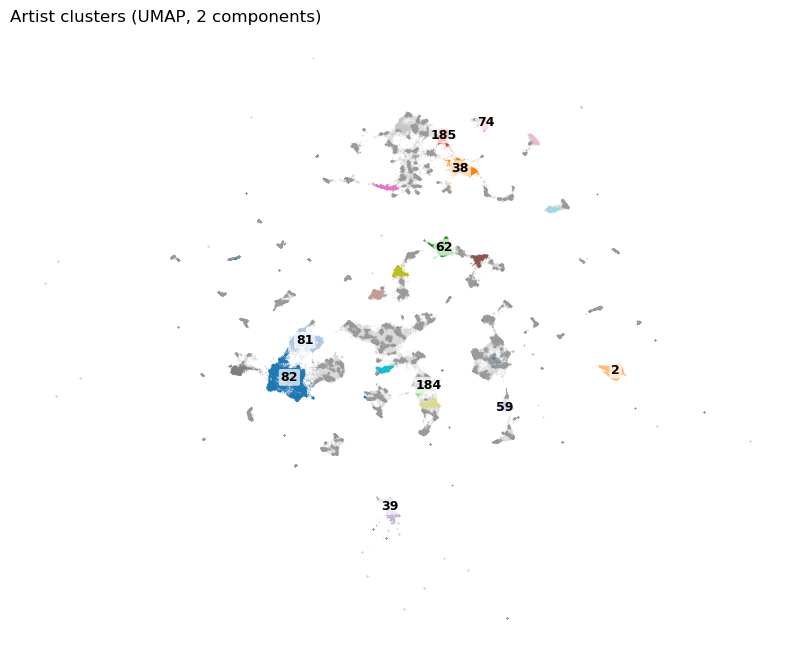

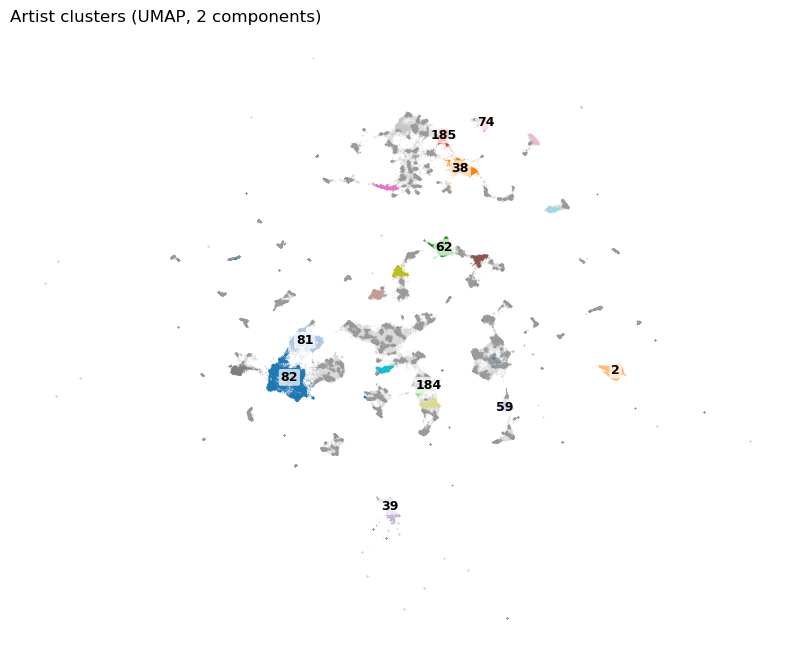

In [9]:
fig = clustering.plot_clusters_2d(embedding_2d, cluster_labels)
print(viz.save_figure(fig, "07_umap_clusters"))
fig

In [10]:
# Top styles, format mix, career span and example artists of each cluster.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 120)
summary = clustering.describe_clusters(cluster_labels, artist_ids, profile_pd, tfidf_pd)
summary.head(30)

,cluster,size,share,is_noise,top_styles,mean_share_vinyl,mean_share_cd,mean_share_cassette,mean_share_file,median_career_span,median_n_releases,median_first_year,examples
0,-1,38098,0.196275,True,"[(Techno, 0.14423582034192428), (Indie Rock, 0.13235038253953024), (Alternative Rock, 0.11569639123066623)]",0.261469,0.143563,0.050902,0.492778,7.0,9.0,2017.0,"[David Bowie, King Gizzard And The Lizard Wizard, Kiss, The Beatles, Depeche Mode]"
1,82,12977,0.066856,False,"[(Experimental, 0.31218042066974355), (Ambient, 0.2941286056515274), (Noise, 0.25582041429144464)]",0.107079,0.082649,0.173094,0.557694,5.0,8.0,2017.0,"[This Is What I Hear When You Talk, Naoki Kasugai, D*Time, TCLB, Buckethead]"
2,81,6231,0.032101,False,"[(Synth-pop, 0.4653079797608702), (Synthwave, 0.3057494728144637), (Electro, 0.2215945441715843)]",0.191312,0.128175,0.057884,0.577389,6.0,9.0,2017.0,"[John Crozier Harrison, Kraftwerk, Closed Mouth, Boy Harsher, Fear Incorporated]"
3,38,5995,0.030885,False,"[(Noise, 0.3179695052717658), (Experimental, 0.30161774162083194), (Ambient, 0.2767747130475812)]",0.141003,0.096844,0.176475,0.488111,7.0,15.0,2017.0,"[Nosferatu 1922, Merzlux, Tole Ache, Eugene Chadbourne, Lord Cernunnos]"
4,2,5379,0.027712,False,"[(Romantic, 0.5299883669257528), (Modern, 0.43546049173912044), (Contemporary, 0.4123991008232602)]",0.056821,0.736937,0.001140,0.123232,9.0,9.0,2016.0,"[Johann Sebastian Bach, Ludwig van Beethoven, Wolfgang Amadeus Mozart, Johannes Brahms, Franz Schubert]"
5,62,4202,0.021648,False,"[(Black Metal, 2.0693931170598767), (Atmospheric Black Metal, 0.26930619539617456), (Depressive Black Metal, 0.14063...",0.258098,0.252097,0.245517,0.182742,6.0,8.0,2018.0,"[Enslaved, Cradle Of Filth, Samael, Dark Funeral, Thy Catafalque]"
6,184,3285,0.016924,False,"[(Punk, 1.5260757218436454), (Pop Punk, 0.20652406794198755), (Post-Punk, 0.13901032136835637)]",0.543479,0.188117,0.135774,0.083145,6.0,7.0,2017.0,"[Sex Pistols, Misfits, Green Day, Ramones, The Offspring]"
7,185,2736,0.014095,False,"[(Techno, 1.125655585271265), (Acid, 0.165280887670996), (Hard Techno, 0.12231687555917595)]",0.277479,0.011753,0.015880,0.680848,8.0,15.0,2017.0,"[Sascha Müller, The Jaffa Kid, MaKaJa Gonzales, M. Rodriguez, DJ Dextro]"
8,74,2581,0.013297,False,"[(Boom Bap, 1.0684109388046796), (Conscious, 0.6505995606023242), (Instrumental, 0.5088597435451899)]",0.434099,0.121153,0.108809,0.235659,8.0,13.0,2017.0,"[Conway The Machine, Mickey Diamond, Westside Gunn, ThaGodFahim, Alchemist]"
9,59,2336,0.012035,False,"[(Soul, 0.8089609736718636), (Funk, 0.4647270883842478), (Disco, 0.30578291563894944)]",0.570164,0.279078,0.010497,0.111179,8.0,8.0,2017.0,"[Black Pumas, Adele (3), Simply Red, Durand Jones & The Indications, Al Green]"


## 6. Compare with other groupings

In [11]:
# Leiden communities on the same collaboration edges (resolution 1.0, seed 42).
graph = networks.to_igraph(collab)
with clustering.timed("Leiden"):
    communities = networks.leiden_communities(graph, resolution=1.0, seed=42)
print("modularity:", communities.attrs["modularity"], "| communities:", communities["community"].nunique())
vs_leiden = clustering.compare_partitions(
    cluster_labels, communities["community"].to_numpy(), artist_ids, communities["node"]
)
print({k: v for k, v in vs_leiden.items() if k != "contingency"})
vs_leiden["contingency"]

[Leiden] 20.7 s


modularity: 0.9104223807407401 | communities: 10015


{'n_common': 63088, 'n_compared': 52807, 'nmi': 0.5744703716379638, 'ari': 0.2993838821114637}


b,4,0,10,14,9,2,28,25,5,18
a,,,,,,,,,,
38,7,5,1028,477,2,21,3,19,4,15
2,2985,0,0,90,1,5,0,0,1206,2
185,1,48,16,14,20,8,21,2,0,23
74,0,2,1,4,4,41,2,926,0,8
148,1,0,55,5,5,5,0,8,0,4
107,0,1867,0,0,54,4,6,1,0,0
198,0,39,0,0,1297,305,10,1,0,0
132,1,0,11,1239,0,0,0,1,0,2
15,0,7,0,3,37,41,12,12,0,41


In [12]:
# Each artist's dominant genre, over the artists that are in both tables.
dominant_genre = networks.artist_dominant_tag(real_artists, release_genres, "genre").select("artist_id", "genre").toPandas()
vs_genre = clustering.compare_partitions(
    cluster_labels, dominant_genre["genre"].to_numpy(), artist_ids, dominant_genre["artist_id"]
)
print({k: v for k, v in vs_genre.items() if k != "contingency"})
vs_genre["contingency"]

{'n_common': 194105, 'n_compared': 156007, 'nmi': 0.3924477281910575, 'ari': 0.06925407287163036}


b,Electronic,Rock,Pop,Hip Hop,Classical,"Folk, World, & Country",Jazz,Funk / Soul,Reggae,Stage & Screen
a,,,,,,,,,,
82,11328,933,76,96,90,102,103,6,0,9
81,4750,906,453,56,5,17,7,13,3,0
38,5394,296,12,29,51,65,43,0,0,6
2,22,10,7,0,5267,26,20,0,0,5
62,81,4107,0,1,5,6,1,0,0,0
184,45,3148,8,8,0,50,2,2,12,1
185,2731,0,1,2,0,1,0,0,0,0
74,101,1,4,2428,0,5,10,21,2,0
59,159,63,120,55,0,124,75,1492,11,4


## Decisions to carry into `main.ipynb`

Filled in from the full-data runs in `executed/`. Each line should end up as a sentence in the report's methodology or limitations.

- [x] Minimum releases per artist: 5 (`min_releases=5`), which keeps 194,105 artists; 63,088 of them are in the collaboration graph (98,440 edges) and get a node2vec embedding.
- [x] node2vec: own NumPy random walks on a SciPy CSR adjacency with gensim Word2Vec (skip-gram), because the `node2vec` package precomputes every second-order transition table and is too slow and too large for this graph. 64 dimensions, 10 walks of 30 steps per node, p = q = 1.
- [x] Feature scaling and block weights: profile block with `log1p` on the counts, then `StandardScaler`; TF-IDF block reduced by truncated SVD (up to 50 components) and L2-normalized; embedding block L2-normalized; each block scaled to a mean squared row norm of about 1, with block weights (1, 1, 1). 122 feature columns in all.
- [x] UMAP and HDBSCAN: UMAP with 30 neighbours, `min_dist` 0.0 and cosine distance, 10 components for clustering and 2 for the plot, run unseeded (a seeded run is single-threaded and takes over an hour per embedding), with the embeddings fixed by the saved files. HDBSCAN from the `hdbscan` package with `min_cluster_size` 100 (`config.HDBSCAN_MIN_CLUSTER_SIZE`), chosen from the sweep 25 / 50 / 100 / 200 (374 / 238 / 149 / 99 clusters, 24% / 20% / 13% / 8% noise): 149 clusters and 13.2% noise. The HDBSCAN cell of this explorer still uses 50 (238 clusters, 19.6% noise).